In [1]:

# imports
import os
import sys
import types
import json
import base64

# figure size/format
fig_width = 7
fig_height = 5
fig_format = 'retina'
fig_dpi = 96
interactivity = ''
is_shiny = False
is_dashboard = False
plotly_connected = True

# matplotlib defaults / format
try:
  import matplotlib.pyplot as plt
  plt.rcParams['figure.figsize'] = (fig_width, fig_height)
  plt.rcParams['figure.dpi'] = fig_dpi
  plt.rcParams['savefig.dpi'] = "figure"

  # IPython 7.14 deprecated set_matplotlib_formats from IPython
  try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
  except ImportError:
    # Fall back to deprecated location for older IPython versions
    from IPython.display import set_matplotlib_formats
    
  set_matplotlib_formats(fig_format)
except Exception:
  pass

# plotly use connected mode
try:
  import plotly.io as pio
  if plotly_connected:
    pio.renderers.default = "notebook_connected"
  else:
    pio.renderers.default = "notebook"
  for template in pio.templates.keys():
    pio.templates[template].layout.margin = dict(t=30,r=0,b=0,l=0)
except Exception:
  pass

# disable itables paging for dashboards
if is_dashboard:
  try:
    from itables import options
    options.dom = 'fiBrtlp'
    options.maxBytes = 1024 * 1024
    options.language = dict(info = "Showing _TOTAL_ entries")
    options.classes = "display nowrap compact"
    options.paging = False
    options.searching = True
    options.ordering = True
    options.info = True
    options.lengthChange = False
    options.autoWidth = False
    options.responsive = True
    options.keys = True
    options.buttons = []
  except Exception:
    pass
  
  try:
    import altair as alt
    # By default, dashboards will have container sized
    # vega visualizations which allows them to flow reasonably
    theme_sentinel = '_quarto-dashboard-internal'
    def make_theme(name):
        nonTheme = alt.themes._plugins[name]    
        def patch_theme(*args, **kwargs):
            existingTheme = nonTheme()
            if 'height' not in existingTheme:
              existingTheme['height'] = 'container'
            if 'width' not in existingTheme:
              existingTheme['width'] = 'container'

            if 'config' not in existingTheme:
              existingTheme['config'] = dict()
            
            # Configure the default font sizes
            title_font_size = 15
            header_font_size = 13
            axis_font_size = 12
            legend_font_size = 12
            mark_font_size = 12
            tooltip = False

            config = existingTheme['config']

            # The Axis
            if 'axis' not in config:
              config['axis'] = dict()
            axis = config['axis']
            if 'labelFontSize' not in axis:
              axis['labelFontSize'] = axis_font_size
            if 'titleFontSize' not in axis:
              axis['titleFontSize'] = axis_font_size  

            # The legend
            if 'legend' not in config:
              config['legend'] = dict()
            legend = config['legend']
            if 'labelFontSize' not in legend:
              legend['labelFontSize'] = legend_font_size
            if 'titleFontSize' not in legend:
              legend['titleFontSize'] = legend_font_size  

            # The header
            if 'header' not in config:
              config['header'] = dict()
            header = config['header']
            if 'labelFontSize' not in header:
              header['labelFontSize'] = header_font_size
            if 'titleFontSize' not in header:
              header['titleFontSize'] = header_font_size    

            # Title
            if 'title' not in config:
              config['title'] = dict()
            title = config['title']
            if 'fontSize' not in title:
              title['fontSize'] = title_font_size

            # Marks
            if 'mark' not in config:
              config['mark'] = dict()
            mark = config['mark']
            if 'fontSize' not in mark:
              mark['fontSize'] = mark_font_size

            # Mark tooltips
            if tooltip and 'tooltip' not in mark:
              mark['tooltip'] = dict(content="encoding")

            return existingTheme
            
        return patch_theme

    # We can only do this once per session
    if theme_sentinel not in alt.themes.names():
      for name in alt.themes.names():
        alt.themes.register(name, make_theme(name))
      
      # register a sentinel theme so we only do this once
      alt.themes.register(theme_sentinel, make_theme('default'))
      alt.themes.enable('default')

  except Exception:
    pass

# enable pandas latex repr when targeting pdfs
try:
  import pandas as pd
  if fig_format == 'pdf':
    pd.set_option('display.latex.repr', True)
except Exception:
  pass

# interactivity
if interactivity:
  from IPython.core.interactiveshell import InteractiveShell
  InteractiveShell.ast_node_interactivity = interactivity

# NOTE: the kernel_deps code is repeated in the cleanup.py file
# (we can't easily share this code b/c of the way it is run).
# If you edit this code also edit the same code in cleanup.py!

# output kernel dependencies
kernel_deps = dict()
for module in list(sys.modules.values()):
  # Some modules play games with sys.modules (e.g. email/__init__.py
  # in the standard library), and occasionally this can cause strange
  # failures in getattr.  Just ignore anything that's not an ordinary
  # module.
  if not isinstance(module, types.ModuleType):
    continue
  path = getattr(module, "__file__", None)
  if not path:
    continue
  if path.endswith(".pyc") or path.endswith(".pyo"):
    path = path[:-1]
  if not os.path.exists(path):
    continue
  kernel_deps[path] = os.stat(path).st_mtime
print(json.dumps(kernel_deps))

# set run_path if requested
run_path = 'L1VzZXJzL2VtYXNyb28xL0xpYnJhcnkvQ2xvdWRTdG9yYWdlL0dvb2dsZURyaXZlLWVtYXNyb28xQHN3YXJ0aG1vcmUuZWR1L015IERyaXZlL1RlYWNoaW5nL0ZhbGwgMjAyNi9FMjEvRGVwbG95ZWQgd2Vic2l0ZSBFMjEvRTIxLUYyNi9MZWN0dXJlcy9MZWMxNw=='
if run_path:
  # hex-decode the path
  run_path = base64.b64decode(run_path.encode("utf-8")).decode("utf-8")
  os.chdir(run_path)

# reset state
%reset

# shiny
# Checking for shiny by using False directly because we're after the %reset. We don't want
# to set a variable that stays in global scope.
if False:
  try:
    import htmltools as _htmltools
    import ast as _ast

    _htmltools.html_dependency_render_mode = "json"

    # This decorator will be added to all function definitions
    def _display_if_has_repr_html(x):
      try:
        # IPython 7.14 preferred import
        from IPython.display import display, HTML
      except:
        from IPython.core.display import display, HTML

      if hasattr(x, '_repr_html_'):
        display(HTML(x._repr_html_()))
      return x

    # ideally we would undo the call to ast_transformers.append
    # at the end of this block whenver an error occurs, we do 
    # this for now as it will only be a problem if the user 
    # switches from shiny to not-shiny mode (and even then likely
    # won't matter)
    import builtins
    builtins._display_if_has_repr_html = _display_if_has_repr_html

    class _FunctionDefReprHtml(_ast.NodeTransformer):
      def visit_FunctionDef(self, node):
        node.decorator_list.insert(
          0,
          _ast.Name(id="_display_if_has_repr_html", ctx=_ast.Load())
        )
        return node

      def visit_AsyncFunctionDef(self, node):
        node.decorator_list.insert(
          0,
          _ast.Name(id="_display_if_has_repr_html", ctx=_ast.Load())
        )
        return node

    ip = get_ipython()
    ip.ast_transformers.append(_FunctionDefReprHtml())

  except:
    pass

def ojs_define(**kwargs):
  import json
  try:
    # IPython 7.14 preferred import
    from IPython.display import display, HTML
  except:
    from IPython.core.display import display, HTML

  # do some minor magic for convenience when handling pandas
  # dataframes
  def convert(v):
    try:
      import pandas as pd
    except ModuleNotFoundError: # don't do the magic when pandas is not available
      return v
    if type(v) == pd.Series:
      v = pd.DataFrame(v)
    if type(v) == pd.DataFrame:
      j = json.loads(v.T.to_json(orient='split'))
      return dict((k,v) for (k,v) in zip(j["index"], j["data"]))
    else:
      return v

  v = dict(contents=list(dict(name=key, value=convert(value)) for (key, value) in kwargs.items()))
  display(HTML('<script type="ojs-define">' + json.dumps(v) + '</script>'), metadata=dict(ojs_define = True))
globals()["ojs_define"] = ojs_define
globals()["__spec__"] = None

{"/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/importlib/_bootstrap.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/importlib/_bootstrap_external.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/zipimport.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/codecs.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/encodings/aliases.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/encodings/__init__.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/encodings/utf_8.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/abc.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/io.py": 1744123930.0, "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/stat.py": 1744123930.0, "/Libr

In [2]:
#| output: asis
#| echo: false

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(4)
A = np.array([[4,1,2],
              [-1/2,3,3/2],
              [0,2,4]],dtype=np.float64)
b = np.array([1,2,1],dtype=np.float64)

# Jacobi's method -- keep using old values

x1 = np.array([1,1,1],dtype=np.float64)
x2 = np.zeros(3)

plt.rcParams["text.usetex"] = True
fig, ax = plt.subplots(figsize=(3, 4))

n_steps = 18

history = np.zeros((n_steps+1,3))
history[0,:] = x1

print("::: {.r-stack}\n")

for i in range(n_steps):
    x2[0] = 1/(A[0,0]) * (b[0] - A[0,1] * x1[1] - A[0,2] * x1[2])
    x2[1] = 1/(A[1,1]) * (b[1] - A[1,0] * x1[0] - A[1,2] * x1[2])
    x2[2] = 1/(A[2,2]) * (b[2] - A[2,0] * x1[0] - A[2,1] * x1[1])

    ax.scatter(range(3), x1, color='crimson', s=50,alpha=(1/n_steps)*(i+1))
    ax.set_title(f"Step {i} $x^{{({i})}}$= [{x1[0]:.4f}, {x1[1]:.4f}, {x1[2]:.4f}]")
    ax.set_ylim(-1.5, 1.5)
    ax.set_xticks(range(3))
    ax.grid(True, linestyle="--", alpha=0.4)

    filename = f"outputs/jacobi1_{i}.png"
    fig.savefig(filename, dpi=150)
    plt.close(fig)

    x1 = x2.copy()
    history[i+1,:] = x2
    fragment_cls = ".fragment" if i > 0 else ""
    print(f"![]({filename}){{width=450px {fragment_cls}}}\n\n")
print(":::\n")

::: {.r-stack}



![](outputs/jacobi1_0.png){width=450px }


![](outputs/jacobi1_1.png){width=450px .fragment}


![](outputs/jacobi1_2.png){width=450px .fragment}


![](outputs/jacobi1_3.png){width=450px .fragment}


![](outputs/jacobi1_4.png){width=450px .fragment}


![](outputs/jacobi1_5.png){width=450px .fragment}




![](outputs/jacobi1_6.png){width=450px .fragment}


![](outputs/jacobi1_7.png){width=450px .fragment}


![](outputs/jacobi1_8.png){width=450px .fragment}


![](outputs/jacobi1_9.png){width=450px .fragment}


![](outputs/jacobi1_10.png){width=450px .fragment}


![](outputs/jacobi1_11.png){width=450px .fragment}


![](outputs/jacobi1_12.png){width=450px .fragment}




![](outputs/jacobi1_13.png){width=450px .fragment}


![](outputs/jacobi1_14.png){width=450px .fragment}


![](outputs/jacobi1_15.png){width=450px .fragment}


![](outputs/jacobi1_16.png){width=450px .fragment}




![](outputs/jacobi1_17.png){width=450px .fragment}


:::



In [3]:
#| echo: true
original = [1, 2, 3]

# "Make a copy" then append only to the new one
assigned = original
assigned.append(4)

print(f"Original (via =):     {original}") 
print(f"Assigned:             {assigned}")

# Make a copy using .copy() then append only to the new one
copied = original.copy()
copied.append(99)

print(f"\nOriginal (via .copy): {original}")
print(f"Copied:               {copied}")

Original (via =):     [1, 2, 3, 4]
Assigned:             [1, 2, 3, 4]

Original (via .copy): [1, 2, 3, 4]
Copied:               [1, 2, 3, 4, 99]


[ 4.  -0.4 -2. ]
[-6.2 -6.4  2.2]
[-15.8  11.6  20.2]
[ 74.2   34.16 -33.8 ]
[  33.88 -131.44 -101.48]
[-598.28  -94.    395.32]


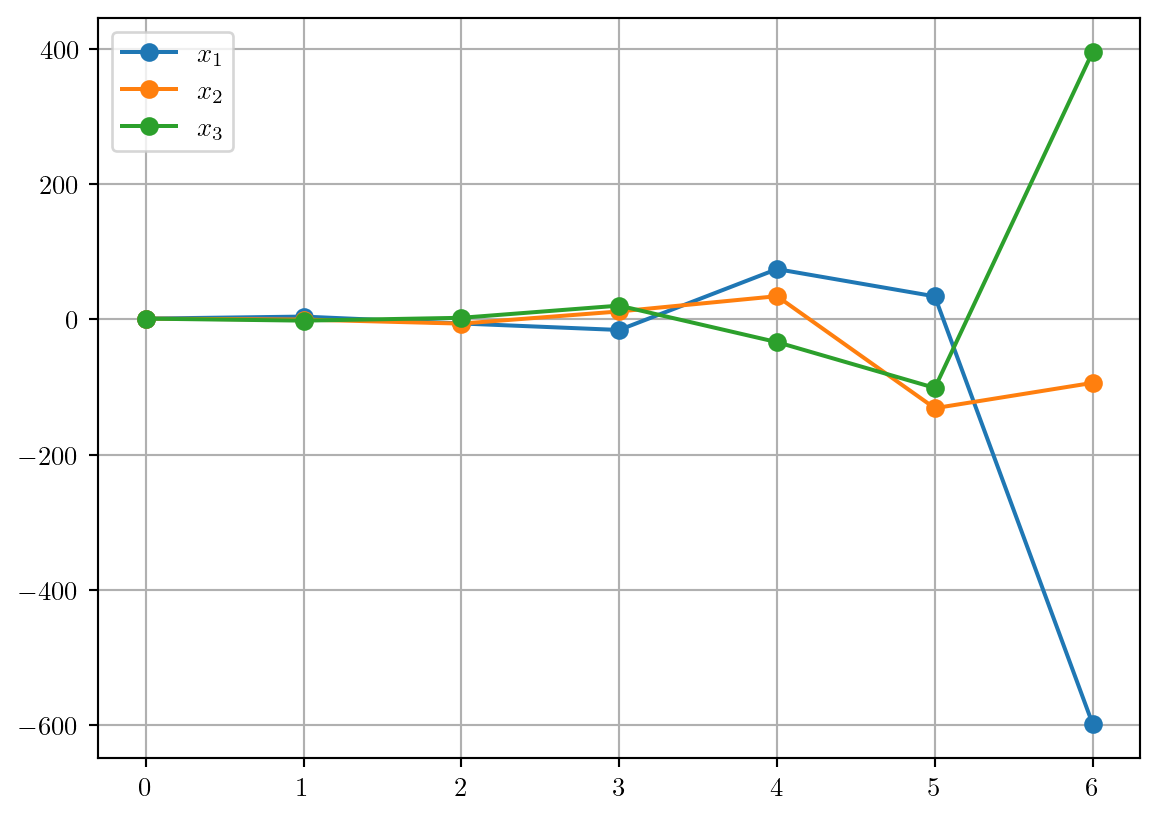

In [4]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(4)
A = np.array([[-1 ,3  ,2 ],
              [4  ,5/2,-1],
              [0  ,3  ,1 ]],dtype=np.float64)
b = np.array([1,2,1],dtype=np.float64)

x1 = np.array([1,1,1],dtype=np.float64)
x2 = np.zeros(3)

n_steps = 6
history = np.zeros((n_steps+1,3))
history[0,:] = x1

for i in range(n_steps):
    x2[0] = 1/(A[0,0]) * (b[0] - A[0,1] * x1[1] - A[0,2] * x1[2])
    x2[1] = 1/(A[1,1]) * (b[1] - A[1,0] * x1[0] - A[1,2] * x1[2])
    x2[2] = 1/(A[2,2]) * (b[2] - A[2,0] * x1[0] - A[2,1] * x1[1])

    print(x2)
    x1 = x2.copy()
    history[i+1,:] = x2

plt.plot(history,'o-',label=['$x_1$','$x_2$','$x_3$'])
plt.grid(True)
plt.legend()
plt.show()

[-0.5     0.3333 -0.25  ]
[0.2917 0.7083 0.0833]
[ 0.0313  0.6736 -0.1042]
[ 0.1337  0.724  -0.0868]
[ 0.1124  0.7323 -0.112 ]
[ 0.1229  0.7414 -0.1162]


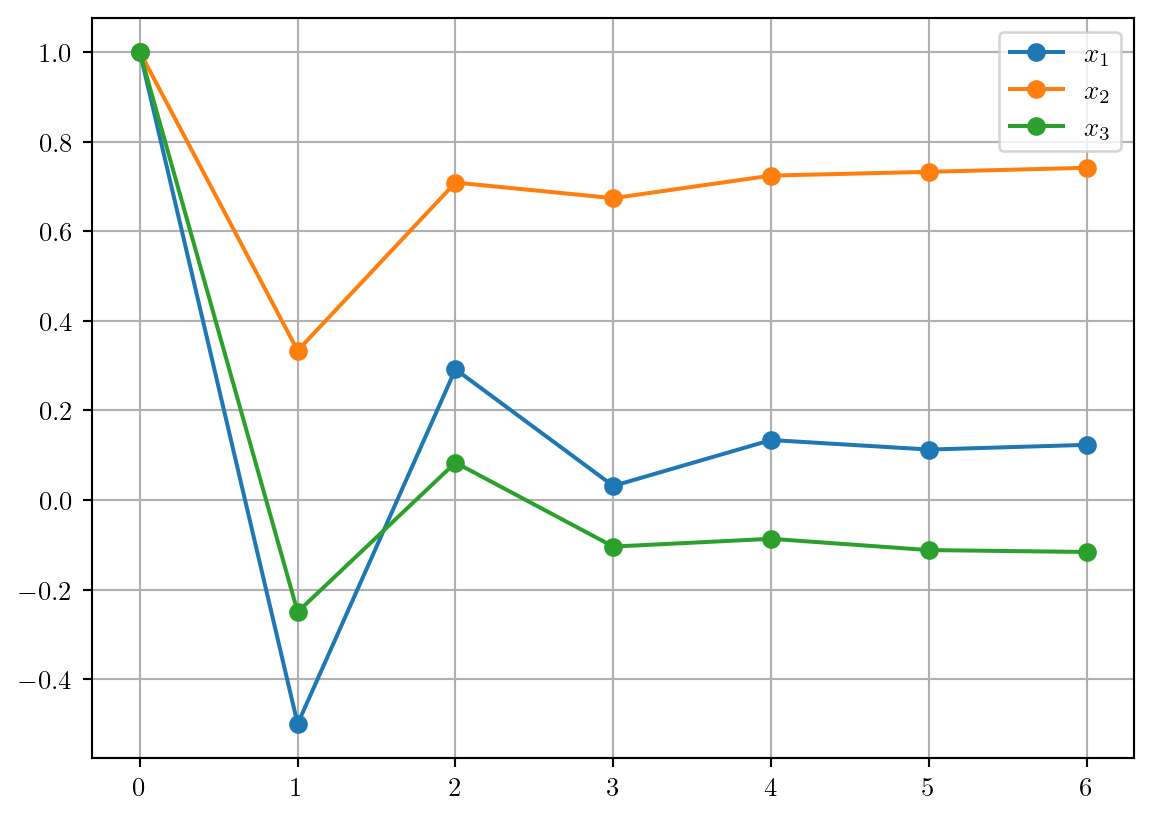

In [5]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(4)
A = np.array([[4   ,1  ,2  ],
              [-1/2,3  ,3/2],
              [0   ,2  ,4  ]],dtype=np.float64)
b = np.array([1,2,1],dtype=np.float64)

x1 = np.array([1,1,1],dtype=np.float64)
x2 = np.zeros(3)

n_steps = 6
history = np.zeros((n_steps+1,3))
history[0,:] = x1

for i in range(n_steps):
    x2[0] = 1/(A[0,0]) * (b[0] - A[0,1] * x1[1] - A[0,2] * x1[2])
    x2[1] = 1/(A[1,1]) * (b[1] - A[1,0] * x1[0] - A[1,2] * x1[2])
    x2[2] = 1/(A[2,2]) * (b[2] - A[2,0] * x1[0] - A[2,1] * x1[1])

    print(x2)
    x1 = x2.copy()
    history[i+1,:] = x2

plt.plot(history,'o-',label=['$x_1$','$x_2$','$x_3$'])
plt.grid(True)
plt.legend()
plt.show()